# 05 — GP on a known 1-D function

Continuous variable only. Checks: the prediction passes through the samples, the modelling
uncertainty is ~0 at the samples and grows between them; all five correlation functions.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mvlse import CORRELATIONS, Continuous, DesignSpace, fit_surrogate

space = DesignSpace({"x": Continuous(0.0, 1.0)})
f = lambda x: np.sin(6 * x) + 0.5 * x
x_train = np.array([0.02, 0.15, 0.30, 0.42, 0.55, 0.70, 0.83, 0.97])
x_grid = np.linspace(0.0, 1.0, 401)
w_train = space.encode([{"x": v} for v in x_train])
w_grid = space.encode([{"x": v} for v in x_grid])
y_train = f(x_train)

rows, fits = [], {}
for corr in CORRELATIONS:
    model = fit_surrogate("hs_dim", space, w_train, y_train, correlation=corr, rng=np.random.default_rng(0))
    mu_s, sd_s = model.predict(w_train)
    mu_g, sd_g = model.predict(w_grid)
    fits[corr] = (mu_g, sd_g)
    rows.append({"correlation": corr,
                 "max |mu - y| at samples": np.abs(mu_s - y_train).max(),
                 "max sd at samples": sd_s.max(),
                 "max sd between samples": sd_g.max(),
                 "RMSE vs truth on grid": np.sqrt(np.mean((mu_g - f(x_grid)) ** 2))})
pd.DataFrame(rows).set_index("correlation")

,max |mu - y| at samples,max sd at samples,max sd between samples,RMSE vs truth on grid
correlation,,,,
squar_exp,2.190699e-05,0.000172,0.001397,0.000117
abs_exp,7.904710e-09,0.000055,0.296122,0.062910
pow_exp,2.191014e-05,0.000172,0.001397,0.000117
matern32,1.649735e-08,0.000064,0.103165,0.020808
matern52,4.869206e-08,0.000087,0.047118,0.011851


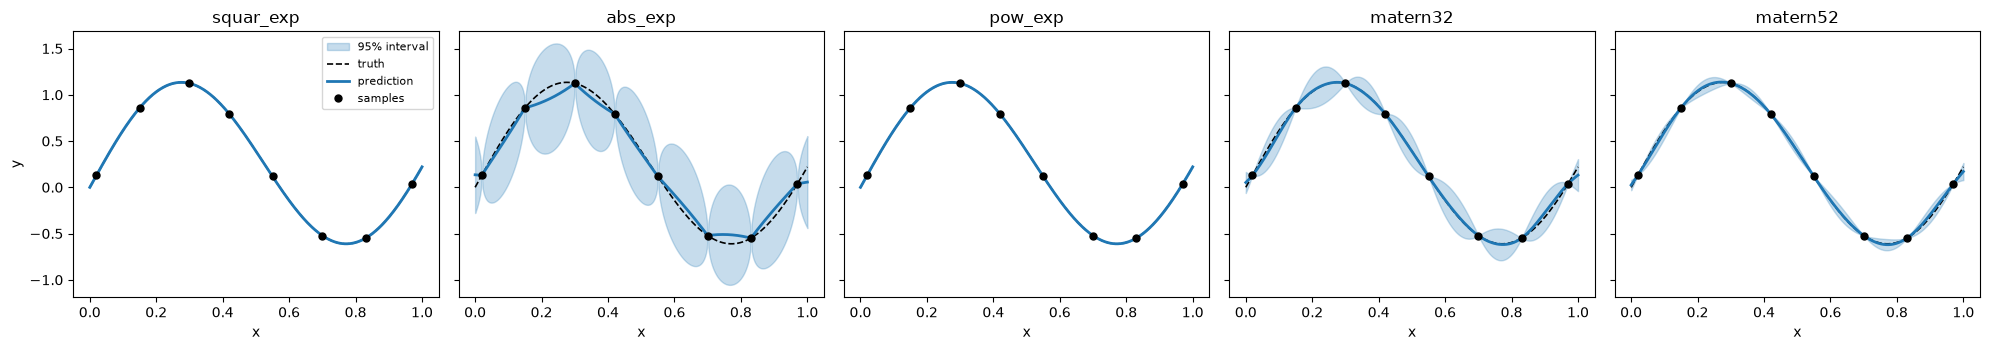

In [2]:
fig, axes = plt.subplots(1, len(fits), figsize=(20, 3.6), sharey=True)
for ax, (corr, (mu, sd)) in zip(axes, fits.items()):
    ax.fill_between(x_grid, mu - 1.96 * sd, mu + 1.96 * sd, color="C0", alpha=0.25, label="95% interval")
    ax.plot(x_grid, f(x_grid), "k--", lw=1.2, label="truth")
    ax.plot(x_grid, mu, "C0", lw=2, label="prediction")
    ax.plot(x_train, y_train, "ko", ms=5, label="samples")
    ax.set_title(corr); ax.set_xlabel("x")
axes[0].set_ylabel("y"); axes[0].legend(fontsize=8)
plt.tight_layout(); plt.show()